# Handling Mixed Variables 


In [1]:
import pandas as pd 
import numpy as np 


In [2]:
df = pd.read_csv('titanic.csv')

In [3]:
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [5]:
df['number'].unique()

<StringArray>
['5', '3', '6', 'A', '2', '1', '4']
Length: 7, dtype: str

Text(0.5, 1.0, 'Passenger Travelling with')

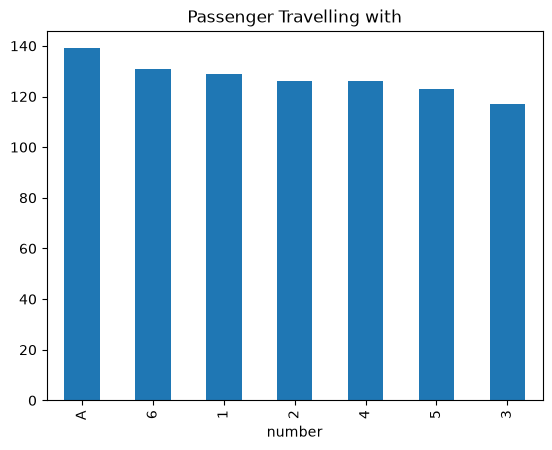

In [6]:
fig = df['number'].value_counts().plot.bar()
fig.set_title('Passenger Travelling with')


In [9]:
# exttract numerical part 
df['number_numerical'] = pd.to_numeric(df['number'],errors='coerce',downcast='integer')

In [10]:
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)
df.head()

,Cabin,Ticket,number,Survived,number_categorical,number_numerical
0,NaN,A/5 21171,5,0,NaN,5.0
1,C85,PC 17599,3,1,NaN,3.0
2,NaN,STON/O2. 3101282,6,1,NaN,6.0
3,C123,113803,3,1,NaN,3.0
4,NaN,373450,A,0,A,NaN


In [12]:
df['Cabin'].unique()

<StringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

In [14]:
df['cabin_num']= df['Cabin'].str.extract('(\d+)')
df['Cabin_cat']= df['Cabin'].str[0]
df.head()

<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\vaibh\AppData\Local\Temp\ipykernel_25980\3243343579.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df['cabin_num']= df['Cabin'].str.extract('(\d+)')


,Cabin,Ticket,number,Survived,number_categorical,number_numerical,cabin_num,Cabin_cat
0,NaN,A/5 21171,5,0,NaN,5.0,NaN,NaN
1,C85,PC 17599,3,1,NaN,3.0,85,C
2,NaN,STON/O2. 3101282,6,1,NaN,6.0,NaN,NaN
3,C123,113803,3,1,NaN,3.0,123,C
4,NaN,373450,A,0,A,NaN,NaN,NaN


<Axes: xlabel='Cabin_cat'>

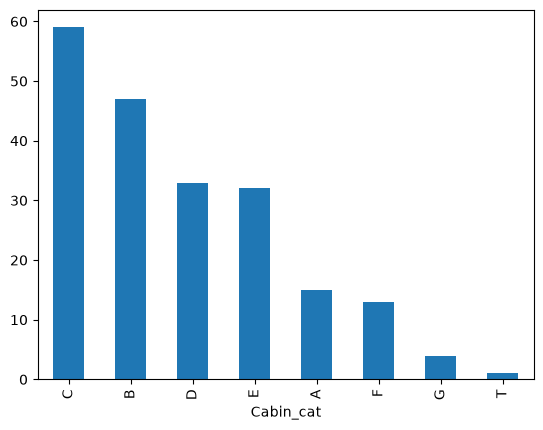

In [16]:
df['Cabin_cat'].value_counts().plot(kind='bar')

In [17]:
import numpy as np
import pandas as pd

# extract the last bit of ticket as number
df['ticket_num'] = df['Ticket'].apply(lambda s: s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                                 errors='coerce',
                                 downcast='integer')

# extract the first part of ticket as category
df['ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(), np.nan,
                            df['ticket_cat'])

df.head(20)


,Cabin,Ticket,number,Survived,number_categorical,number_numerical,cabin_num,Cabin_cat,ticket_num,ticket_cat
0,NaN,A/5 21171,5,0,NaN,5.0,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,NaN,3.0,85,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,NaN,6.0,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,NaN,3.0,123,C,113803.0,NaN
4,NaN,373450,A,0,A,NaN,NaN,NaN,373450.0,NaN
5,NaN,330877,2,0,NaN,2.0,NaN,NaN,330877.0,NaN
6,E46,17463,2,0,NaN,2.0,46,E,17463.0,NaN
7,NaN,349909,5,0,NaN,5.0,NaN,NaN,349909.0,NaN
8,NaN,347742,1,1,NaN,1.0,NaN,NaN,347742.0,NaN
9,NaN,237736,A,1,A,NaN,NaN,NaN,237736.0,NaN
